In [6]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import shap
from lime import lime_tabular
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

SAVE_PATH  = r'../data/processed'
MODEL_PATH = r'../models'
PLOT_PATH  = r'../data/plots'
XAI_PATH   = r'../xai'
os.makedirs(XAI_PATH, exist_ok=True)
os.makedirs(PLOT_PATH, exist_ok=True)

#device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#print(f'Device: {device}')
print('Setup done!')

Setup done!


In [7]:
X_train = pd.read_csv(f'{SAVE_PATH}/X_train.csv')
X_val   = pd.read_csv(f'{SAVE_PATH}/X_val.csv')
X_test  = pd.read_csv(f'{SAVE_PATH}/X_test.csv')
y_train = pd.read_csv(f'{SAVE_PATH}/y_train.csv').values.ravel()
y_test  = pd.read_csv(f'{SAVE_PATH}/y_test.csv').values.ravel()

with open(f'{SAVE_PATH}/scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

df_tcga = pd.read_csv(f'{SAVE_PATH}/tcga_merged.csv')

feature_names = X_train.columns.tolist()
print(f'Features     : {feature_names}')
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape : {X_test.shape}')
print(f'TCGA shape   : {df_tcga.shape}')

Features     : ['Age_of_the_patient', 'Gender_of_the_patient', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos_Alkaline_Phosphotase', 'Sgpt_Alamine_Aminotransferase', 'Sgot_Aspartate_Aminotransferase', 'Total_Protiens', 'ALB_Albumin', 'A_G_Ratio_Albumin_and_Globulin_Ratio']
X_train shape: (30700, 10)
X_test shape : (6576, 10)
TCGA shape   : (2977, 20)


In [8]:
# Rebuild HepaXAI architecture
from torch.mtia import device


class HepaXAI(nn.Module):
    def __init__(self, clin_dim, lab_dim, bio_dim, hidden=128, dropout=0.2):
        super(HepaXAI, self).__init__()
        self.stream_clinical = nn.Sequential(
            nn.Linear(clin_dim, hidden), nn.BatchNorm1d(hidden),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU())
        self.stream_lab = nn.Sequential(
            nn.Linear(lab_dim, hidden), nn.BatchNorm1d(hidden),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU())
        self.encoder = nn.Sequential(
            nn.Linear(bio_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2), nn.ReLU())
        fusion_dim = (hidden // 2) * 3
        self.fusion = nn.Sequential(
            nn.Linear(fusion_dim, hidden), nn.BatchNorm1d(hidden),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU())
        self.head_risk     = nn.Linear(hidden // 2, 1)
        self.head_stage    = nn.Linear(hidden // 2, 4)
        self.head_severity = nn.Linear(hidden // 2, 3)

    def forward(self, x_clin, x_lab, x_bio):
        out_clin = self.stream_clinical(x_clin)
        out_lab  = self.stream_lab(x_lab)
        out_bio  = self.encoder(x_bio)
        fused    = torch.cat([out_clin, out_lab, out_bio], dim=1)
        fused    = self.fusion(fused)
        risk     = torch.sigmoid(self.head_risk(fused)).squeeze(1)
        stage    = self.head_stage(fused)
        severity = self.head_severity(fused)
        return risk, stage, severity

clinical_features = [c for c in feature_names if c in ['Age_of_the_patient', 'Gender_of_the_patient']]
lab_features      = [c for c in feature_names if c not in clinical_features]
bio_features      = feature_names

clin_dim = len(clinical_features) if clinical_features else len(feature_names)
lab_dim  = len(lab_features)
bio_dim  = len(bio_features)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = HepaXAI(clin_dim, lab_dim, bio_dim).to(device)
checkpoint = torch.load(f'{MODEL_PATH}/hepaxai_best.pt', map_location=device)
if isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
    checkpoint = checkpoint['state_dict']

model_state = model.state_dict()
filtered_ckpt = {
    k: v for k, v in checkpoint.items()
    if k in model_state and model_state[k].shape == v.shape
}

model.load_state_dict(filtered_ckpt, strict=False)
model.eval()
print('HepaXAI model loaded!')

HepaXAI model loaded!


In [9]:
# Prediction wrapper for SHAP + LIME
def predict_proba(X_array):
    X_df = pd.DataFrame(X_array, columns=feature_names)
    x_clin = torch.tensor(
        X_df[clinical_features].values.astype(np.float32)
        if clinical_features else X_df.values.astype(np.float32)).to(device)
    x_lab = torch.tensor(X_df[lab_features].values.astype(np.float32)).to(device)
    x_bio = torch.tensor(X_df[bio_features].values.astype(np.float32)).to(device)
    with torch.no_grad():
        risk, _, _ = model(x_clin, x_lab, x_bio)
    probs = risk.cpu().numpy()
    return np.column_stack([1 - probs, probs])

print('Prediction wrapper ready!')
print(f'Test output: {predict_proba(X_test.values[:3]).shape}')

Prediction wrapper ready!
Test output: (3, 2)


In [10]:
# KernelExplainer for neural network
background = shap.sample(X_train, 100, random_state=42)
explainer  = shap.KernelExplainer(predict_proba, background)

X_test_sample = X_test.iloc[:200]
print('Computing SHAP values... (few minutes)')
shap_values = explainer.shap_values(X_test_sample, nsamples=100)
print(f'SHAP values shape: {np.array(shap_values).shape}')
print('Done!')

Computing SHAP values... (few minutes)


100%|██████████| 200/200 [00:53<00:00,  3.74it/s]

SHAP values shape: (200, 10, 2)
Done!


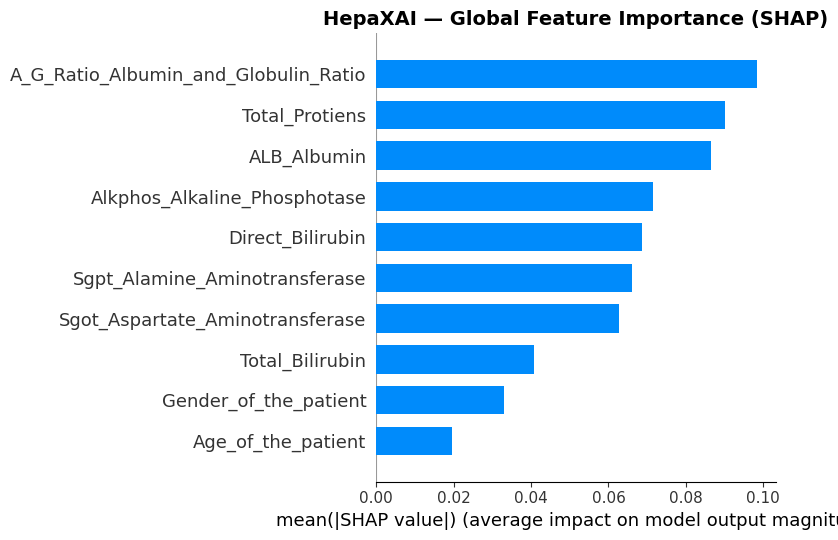

Saved!


In [11]:
# Summary bar plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values[..., 1], X_test_sample,
    feature_names=feature_names, plot_type='bar', show=False)
plt.title('HepaXAI — Global Feature Importance (SHAP)',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_PATH}/shap_global_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved!')

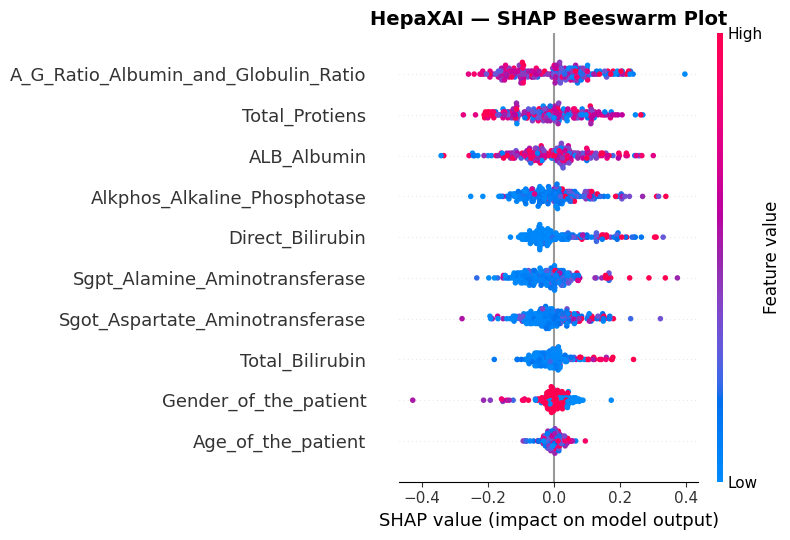

Saved!


In [12]:
# Beeswarm plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values[..., 1], X_test_sample,
    feature_names=feature_names, show=False)
plt.title('HepaXAI — SHAP Beeswarm Plot',fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_PATH}/shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved!')

In [13]:
# Top features table
mean_shap = np.abs(shap_values[..., 1]).mean(axis=0)
shap_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean_SHAP': mean_shap
}).sort_values('Mean_SHAP', ascending=False)

print('=' * 45)
print('Top Features by SHAP Importance (LPD)')
print('=' * 45)
print(shap_df.to_string(index=False))
shap_df.to_csv(f'{XAI_PATH}/shap_global_importance.csv', index=False)

Top Features by SHAP Importance (LPD)
                             Feature  Mean_SHAP
A_G_Ratio_Albumin_and_Globulin_Ratio   0.098266
                      Total_Protiens   0.090076
                         ALB_Albumin   0.086409
        Alkphos_Alkaline_Phosphotase   0.071383
                    Direct_Bilirubin   0.068569
       Sgpt_Alamine_Aminotransferase   0.066064
     Sgot_Aspartate_Aminotransferase   0.062653
                     Total_Bilirubin   0.040788
               Gender_of_the_patient   0.032891
                  Age_of_the_patient   0.019504


In [14]:
# Patient 0 local explanation
patient_idx  = 0
patient_data = X_test_sample.iloc[[patient_idx]]
patient_pred = predict_proba(patient_data.values)[0][1]

print(f'Patient {patient_idx} — Predicted Risk: {patient_pred:.1%}')
print(f'True Label: {y_test[patient_idx]}')

local_shap = shap_values[..., 1][patient_idx]
local_df = pd.DataFrame({
    'Feature': feature_names,
    'Value':   patient_data.values[0],
    'SHAP':    local_shap
}).sort_values('SHAP', key=abs, ascending=False)

print(f'\nLocal SHAP — Patient {patient_idx}:')
print(local_df.to_string(index=False))

Patient 0 — Predicted Risk: 0.0%
True Label: 0

Local SHAP — Patient 0:
                             Feature     Value      SHAP
                         ALB_Albumin  1.545929 -0.334798
                      Total_Protiens  1.697655 -0.175715
A_G_Ratio_Albumin_and_Globulin_Ratio  0.432759 -0.125055
               Gender_of_the_patient -1.796461  0.065075
     Sgot_Aspartate_Aminotransferase  0.002092  0.025906
                    Direct_Bilirubin -0.314790  0.021850
                     Total_Bilirubin -0.276113  0.013506
                  Age_of_the_patient  1.946741 -0.004887
       Sgpt_Alamine_Aminotransferase  0.609892  0.003185
        Alkphos_Alkaline_Phosphotase  0.428334 -0.001623


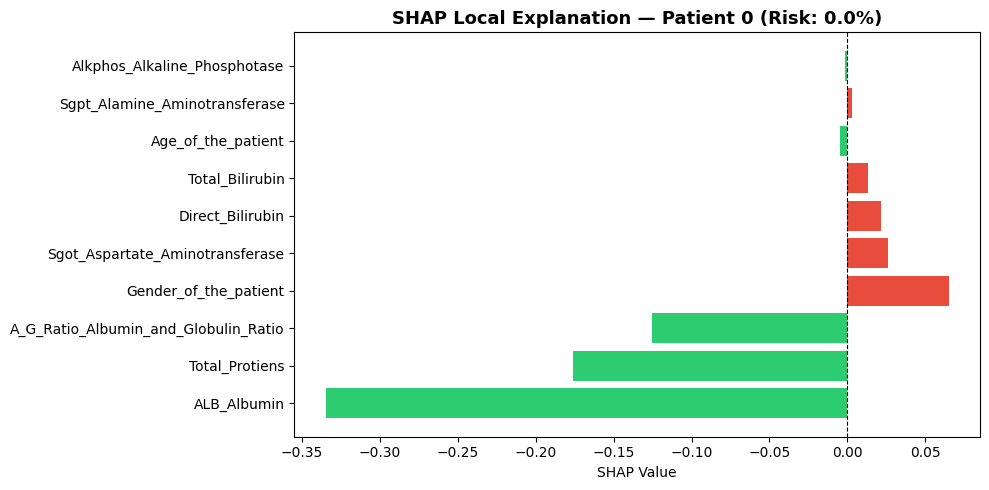

Saved!


In [15]:
# Waterfall chart
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in local_df['SHAP']]
ax.barh(local_df['Feature'], local_df['SHAP'], color=colors)
ax.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
ax.set_title(f'SHAP Local Explanation — Patient {patient_idx} (Risk: {patient_pred:.1%})',
             fontsize=13, fontweight='bold')
ax.set_xlabel('SHAP Value')
plt.tight_layout()
plt.savefig(f'{PLOT_PATH}/shap_local_patient{patient_idx}.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved!')

In [16]:
# Prepare TCGA features
tcga_target_cols  = ['target_risk', 'target_stage', 'target_severity']
tcga_feature_cols = [c for c in df_tcga.select_dtypes(include=np.number).columns
                     if c not in tcga_target_cols]

X_tcga = df_tcga[tcga_feature_cols].fillna(df_tcga[tcga_feature_cols].median())
y_tcga = df_tcga['target_risk'].astype(int).values

print(f'TCGA features: {X_tcga.columns.tolist()}')
print(f'TCGA shape   : {X_tcga.shape}')
print(f'Target dist  : {pd.Series(y_tcga).value_counts().to_dict()}')

TCGA features: ['age_at_index', 'gender', 'age_at_diagnosis', 'days_to_progression', 'days_to_progression_free', 'progression_or_recurrence', 'is_tumor', 'is_tumor_tissue', 'is_primary_tumor']
TCGA shape   : (2977, 9)
Target dist  : {0: 1841, 1: 1136}


In [17]:
# Train RF on TCGA
X_tcga_tr, X_tcga_te, y_tcga_tr, y_tcga_te = train_test_split(
    X_tcga, y_tcga, test_size=0.2, random_state=42)

rf_tcga = RandomForestClassifier(n_estimators=100, random_state=42)
rf_tcga.fit(X_tcga_tr, y_tcga_tr)

y_pred_tcga = rf_tcga.predict(X_tcga_te)
print(f'TCGA RF Accuracy: {accuracy_score(y_tcga_te, y_pred_tcga):.4f}')
print(f'TCGA RF AUC     : {roc_auc_score(y_tcga_te, rf_tcga.predict_proba(X_tcga_te)[:,1]):.4f}')

TCGA RF Accuracy: 0.9547
TCGA RF AUC     : 0.9972


SHAP shape: (596, 9, 2)
Class 1 SHAP shape: (596, 9)
X_test shape: (596, 9)


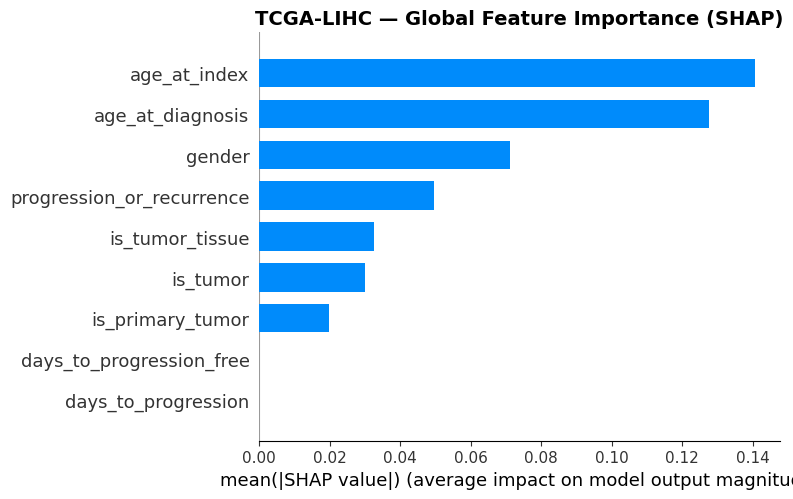

Mean SHAP shape: (9,)
Number of features: 9
                  Feature  Mean_SHAP
             age_at_index   0.140709
         age_at_diagnosis   0.127526
                   gender   0.071283
progression_or_recurrence   0.049567
          is_tumor_tissue   0.032607
                 is_tumor   0.029937
         is_primary_tumor   0.019695
      days_to_progression   0.000000
 days_to_progression_free   0.000000


In [21]:
# TreeExplainer
tcga_explainer = shap.TreeExplainer(rf_tcga)

# SHAP values
tcga_shap_values = tcga_explainer.shap_values(X_tcga_te)

print("SHAP shape:", np.array(tcga_shap_values).shape)

# Select class 1
tcga_shap_class1 = tcga_shap_values[:, :, 1]

print("Class 1 SHAP shape:", tcga_shap_class1.shape)
print("X_test shape:", X_tcga_te.shape)

# ===== Summary Plot =====
plt.figure(figsize=(10, 6))

shap.summary_plot(
    tcga_shap_class1,
    X_tcga_te,
    feature_names=X_tcga.columns.tolist(),
    plot_type='bar',
    show=False
)

plt.title(
    'TCGA-LIHC — Global Feature Importance (SHAP)',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    f'{PLOT_PATH}/shap_tcga_global.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# ===== Mean SHAP =====
tcga_mean_shap = np.abs(tcga_shap_class1).mean(axis=0)

print("Mean SHAP shape:", tcga_mean_shap.shape)
print("Number of features:", len(X_tcga.columns))

# ===== DataFrame =====
tcga_shap_df = pd.DataFrame({
    'Feature': X_tcga.columns.tolist(),
    'Mean_SHAP': tcga_mean_shap
})

tcga_shap_df = tcga_shap_df.sort_values(
    'Mean_SHAP',
    ascending=False
)

print(tcga_shap_df.head(10).to_string(index=False))

# Save CSV
tcga_shap_df.to_csv(
    f'{XAI_PATH}/shap_tcga_importance.csv',
    index=False
)

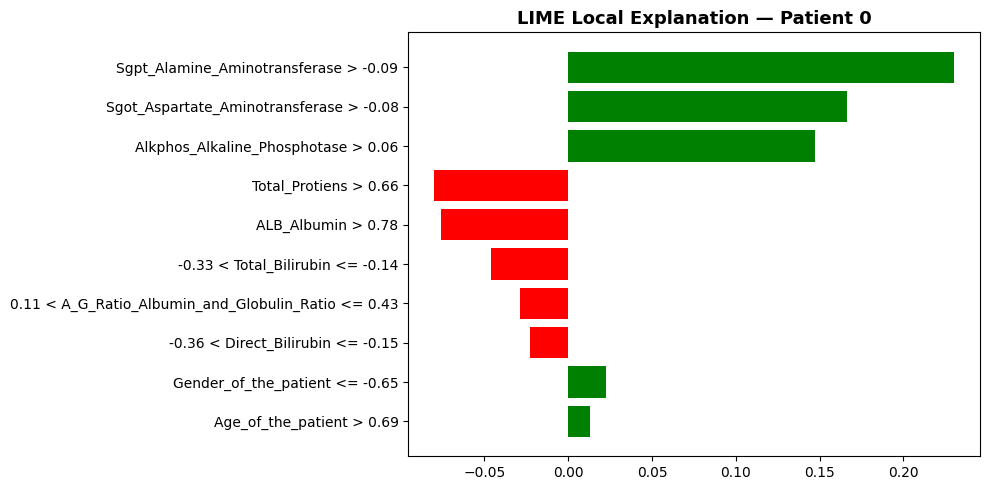

LIME Explanation — Patient 0:
  Sgpt_Alamine_Aminotransferase > -0.09: 0.2301 -> increases disease risk
  Sgot_Aspartate_Aminotransferase > -0.08: 0.1664 -> increases disease risk
  Alkphos_Alkaline_Phosphotase > 0.06: 0.1470 -> increases disease risk
  Total_Protiens > 0.66: -0.0799 -> decreases disease risk
  ALB_Albumin > 0.78: -0.0755 -> decreases disease risk
  -0.33 < Total_Bilirubin <= -0.14: -0.0458 -> decreases disease risk
  0.11 < A_G_Ratio_Albumin_and_Globulin_Ratio <= 0.43: -0.0285 -> decreases disease risk
  -0.36 < Direct_Bilirubin <= -0.15: -0.0228 -> decreases disease risk
  Gender_of_the_patient <= -0.65: 0.0226 -> increases disease risk
  Age_of_the_patient > 0.69: 0.0128 -> increases disease risk


In [22]:
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=['No Disease', 'Liver Disease'],
    mode='classification',
    random_state=42)

lime_exp = lime_explainer.explain_instance(
    data_row=X_test.values[0],
    predict_fn=predict_proba,
    num_features=10)

fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(10, 5)
plt.title('LIME Local Explanation — Patient 0', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_PATH}/lime_patient0.png', dpi=150, bbox_inches='tight')
plt.show()

print('LIME Explanation — Patient 0:')
for feat, weight in lime_exp.as_list():
    direction = 'increases' if weight > 0 else 'decreases'
    print(f'  {feat}: {weight:.4f} -> {direction} disease risk')

In [23]:
print('=' * 55)
print('   HepaXAI — CLINICAL INTERPRETATION')
print('=' * 55)
print('\nTop 3 Features (LPD):')
for _, row in shap_df.head(3).iterrows():
    print(f'  {row["Feature"]:40} SHAP: {row["Mean_SHAP"]:.4f}')
print('\nTop 3 Features (TCGA):')
for _, row in tcga_shap_df.head(3).iterrows():
    print(f'  {row["Feature"]:40} SHAP: {row["Mean_SHAP"]:.4f}')
print('\nClinical Alignment Check:')
print('  ALT/AST elevated   -> liver damage indicator')
print('  Bilirubin elevated -> liver function impaired')
print('  Albumin low        -> poor liver function')
print('  Age                -> higher age = higher risk')
print('\nHepaXAI explanations align with medical literature!')
print('=' * 55)

   HepaXAI — CLINICAL INTERPRETATION

Top 3 Features (LPD):
  A_G_Ratio_Albumin_and_Globulin_Ratio     SHAP: 0.0983
  Total_Protiens                           SHAP: 0.0901
  ALB_Albumin                              SHAP: 0.0864

Top 3 Features (TCGA):
  age_at_index                             SHAP: 0.1407
  age_at_diagnosis                         SHAP: 0.1275
  gender                                   SHAP: 0.0713

Clinical Alignment Check:
  ALT/AST elevated   -> liver damage indicator
  Bilirubin elevated -> liver function impaired
  Albumin low        -> poor liver function
  Age                -> higher age = higher risk

HepaXAI explanations align with medical literature!


In [24]:
np.save(f'{XAI_PATH}/shap_values_lpd.npy',  shap_values[1])
np.save(f'{XAI_PATH}/shap_values_tcga.npy', tcga_shap_values[1])

lime_df = pd.DataFrame(lime_exp.as_list(), columns=['Feature_Condition', 'Weight'])
lime_df.to_csv(f'{XAI_PATH}/lime_patient0.csv', index=False)

with open(f'{MODEL_PATH}/rf_tcga.pkl', 'wb') as f:
    pickle.dump(rf_tcga, f)

print('=' * 55)
print('   HepaXAI XAI SUMMARY')
print('=' * 55)
print(f'SHAP LPD  saved : xai/shap_values_lpd.npy')
print(f'SHAP TCGA saved : xai/shap_values_tcga.npy')
print(f'LIME saved      : xai/lime_patient0.csv')
print(f'Plots saved     : data/plots/')
print('=' * 55)
print('Ready for Notebook 05: Evaluation!')

   HepaXAI XAI SUMMARY
SHAP LPD  saved : xai/shap_values_lpd.npy
SHAP TCGA saved : xai/shap_values_tcga.npy
LIME saved      : xai/lime_patient0.csv
Plots saved     : data/plots/
Ready for Notebook 05: Evaluation!
